## Лабораторная работа №1 | Вариант 4

Выполнил: Лахтин Владимир Владиславович М80-313БВ-24

### 1. Numpy

In [1]:
import numpy as np

1. Найти индексы не нулевых элементов массива [1,2,0,0,4,0]

In [2]:
arr = [1, 2, 0, 0, 4, 0]
non_zero_indices = np.nonzero(arr)
print(non_zero_indices)

(array([0, 1, 4]),)


2. Создайте единичную матрицу размером 3х3

In [3]:
identity_matrix = np.eye(3)
print(identity_matrix)

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


3. Создайте матрицу-шахматную доску 8х8 используя функцию `tile`

In [4]:
block = np.array([[1, 0], [0, 1]])
chess_desk = np.tile(block, (4, 4))
print(chess_desk)

[[1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]
 [1 0 1 0 1 0 1 0]
 [0 1 0 1 0 1 0 1]]


4. Дан 1D массив, удалите все элементы которые входят в диапазон `[3, 8]` inplace

In [5]:
arr = np.array([0, 4, 4, 2, 1, 4, 8, 7, 10, 15])
mask = (arr < 3) | (arr > 8)
arr = arr[mask]
print(arr)

[ 0  2  1 10 15]


5. Создайте случайный вектор размером 10 элементов и замените максимальный элемент на 0

In [6]:
vector = np.random.randint(low = 0, high = 1000, size = 10)
print("vector: ", vector)
vector[np.argmax(vector)] = 0
print("edited vector", vector)

vector:  [160 204 858 894 553 850 591 447 696 116]
edited vector [160 204 858   0 553 850 591 447 696 116]


6. Как распечатать все значения в массиве?

In [7]:
large_array = np.arange(2000)
#np.set_printoptions(threshold = np.inf)
print(large_array)

[   0    1    2 ... 1997 1998 1999]


7. Рассмотрим случайный вектор с формой 100х2, представляющей координаты, и найдем расстояния от точки к точке

In [8]:
points = np.random.random((100, 2)) * 10

diff = points[:, np.newaxis, :] - points[np.newaxis, :, :]
distances = np.sqrt(np.sum(diff ** 2, axis=-1))

print("final matrix's shape: ", distances.shape)
print("distance", distances[0, 1])

final matrix's shape:  (100, 100)
distance 4.919645929307659


8. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [9]:
arr = np.array([1.7, 2.3, -3.9, 4.0], dtype=np.float32)
print("array was created at ", arr.__array_interface__['data'][0])

arr_int = arr.view(np.int32)
np.trunc(arr, out=arr_int, casting='unsafe')
arr = arr_int

print("result:", arr, arr.dtype)
print("result array is at   ", arr.__array_interface__['data'][0])

array was created at  119564048
result: [ 1  2 -3  4] int32
result array is at    119564048


9. Как прочитать заданный файл?
```
1, 2, 3, 4, 5
6,  ,  , 7, 8
 ,  , 9,10,11
```

In [10]:
import io

file_content = """
1, 2, 3, 4, 5
6,  ,  , 7, 8
 ,  , 9,10,11
"""

data = np.genfromtxt(io.StringIO(file_content), delimiter=',', filling_values=np.nan)
print(data)

[[ 1.  2.  3.  4.  5.]
 [ 6. nan nan  7.  8.]
 [nan nan  9. 10. 11.]]


10. Какой эквивалент enumerate для numpy массивов?

In [11]:
arr = np.arange(20, 200, 2)

#for index, value in np.ndenumerate(arr):
    #print(f"index {index[0]} : value {value}")

### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом

Файл: `russian-housing-market.csv`

```
price_doc - Цена продажи
id - Id транзакции
timestamp - Дата транзакции
full_sq - суммарная площадь в квадратных метрах, включая лоджию, валконы и отдельные нежилые помещения
life_sq - жилая площаль в квадратных метрах, исключая лоджии, балконы и прочие нежилые помещения
floor - для апартаментов, этаж помещения
max_floor - количество этажей в здании
material - материал стен
build_year - год постройки
num_room - количество жилых комнат
kitch_sq - площадь кухни
state - состояние апартаментов
product_type - покупка или инвестиция собственника-арендатора
sub_area - название района
```

In [12]:
import pandas as pd

In [15]:
# Load dataset here
df = pd.read_csv('russian-housing-market.csv')

1. Посчитайте количество записей в датасете с отсутствующей информацией о жилой площади жилого помещения

In [16]:
missing_count = df['life_sq'].isnull().sum()
print(f"missing life square count: {missing_count}")

missing life square count: 6383


2. Предложите способ заменить отсутствующие значения из пункта 1 и реализуйте его. Способ нужно аргументировать(сказать почему это достаточно хорошее приближение)

In [25]:
ratio = df['life_sq'] / df['full_sq']
median_ratio = ratio.median()

missing_indices = df[df['life_sq'].isnull()].index

df.loc[missing_indices, 'life_sq'] = df.loc[missing_indices, 'full_sq'] * median_ratio

print(f"number of missing life square: {df['life_sq'].isnull().sum()}")

number of missing life square: 0


Логично заполнить отсутствующую жилплощадь для квартир в согласии с
медианным отношением оной для квартир, где она есть базово.
Такое значение будет более вероятно, чем просто случаейное заполнение,
будет корректно с точки зрения того, что жилая площадь - это какая-то часть
от общей. Базово этого способа вполне достаточно для более-менее нормального заполнения отсутствующей информации, а также такое заполнение не исказит исходное отношение в целом по такой таблице.



3. Какие значения имеет 25, 50 и 75 перцентили полной площади помещения

In [19]:
percentiles = df['full_sq'].quantile([0.25, 0.5, 0.75])
print(percentiles)

0.25    38.0
0.50    49.0
0.75    63.0
Name: full_sq, dtype: float64


4. Посчитайте среднюю стоимость продажи помещений с общей площадью от 50 до 70 квадратных метров

In [27]:
filtered_df = df[(df['full_sq'] >= 50) & (df['full_sq'] <= 70)]

average_price = filtered_df['price_doc'].mean()
print(f"Average price: {average_price.round(2)}")

Average price: 7243041.19


5. Какая максимальная этажность здания представлена в датасете

In [28]:
max_floors = df['max_floor'].max()
print(f"maximal floor count: {max_floors}")

maximal floor count: 117.0


6. Выявите район с самым дорогим жильем

In [29]:
most_expensive_district = df.groupby('sub_area')['price_doc'].mean().idxmax()
print(f"most expensive (on average) district: {most_expensive_district}")

most expensive (on average) district: Hamovniki


7. Посчитайте среднюю стоимость за квадратный метр жилья в Митино(Mitino)

In [31]:
df['price_per_sqm'] = df['price_doc'] / df['full_sq']
mitino_avg_price_per_sqm = df[df['sub_area'] == 'Mitino']['price_per_sqm'].mean()
print(f"average pricea per square meter in Mitino: {mitino_avg_price_per_sqm.round(2)}")

average pricea per square meter in Mitino: 171841.4


8. Посчитайте среднюю площадь комнаты в Бибирево

In [33]:
df['room_area'] = df['life_sq'] / df['num_room']
bibirevo_avg_room_area = df[df['sub_area'] == 'Bibirevo']['room_area'].mean()

print(f"average room square in Bibirevo: {bibirevo_avg_room_area.round(2)}")

average room square in Bibirevo: 16.06


9. Проанализируйте есть ли разница в цене между квартирами на 1 и 9 этажах

In [37]:
first_floor = df[df['floor'] == 1]['price_doc']
ninth_floor = df[df['floor'] == 9]['price_doc']

avg_price_1 = first_floor.mean()
avg_price_9 = ninth_floor.mean()

print(f"average price 1st floor: {avg_price_1.round(2)}")
print(f"average price 9th floor: {avg_price_9.round(2)}")
print(f"diff: {(avg_price_9 - avg_price_1).round(2)}")

average price 1st floor: 5739379.59
average price 9th floor: 6937582.58
diff: 1198203.0


10. Найдите минимальную стоимость квартиры с жилой площадью не менее 60 квадратных метров, не менее чем 3мя комнатами и не ниже чем на 5 этаже

In [38]:
filtered_df = df[
    (df['life_sq'] >= 60) &
    (df['num_room'] >= 3) &
    (df['floor'] >= 5)
]

min_price = filtered_df['price_doc'].min()
print(f"minimal price by filters: {min_price}")

minimal price by filters: 1000000


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

1. Как менялась средняя цена квартиры в Нагатинском Затоне(Nagatinski Zaton) с течением времени

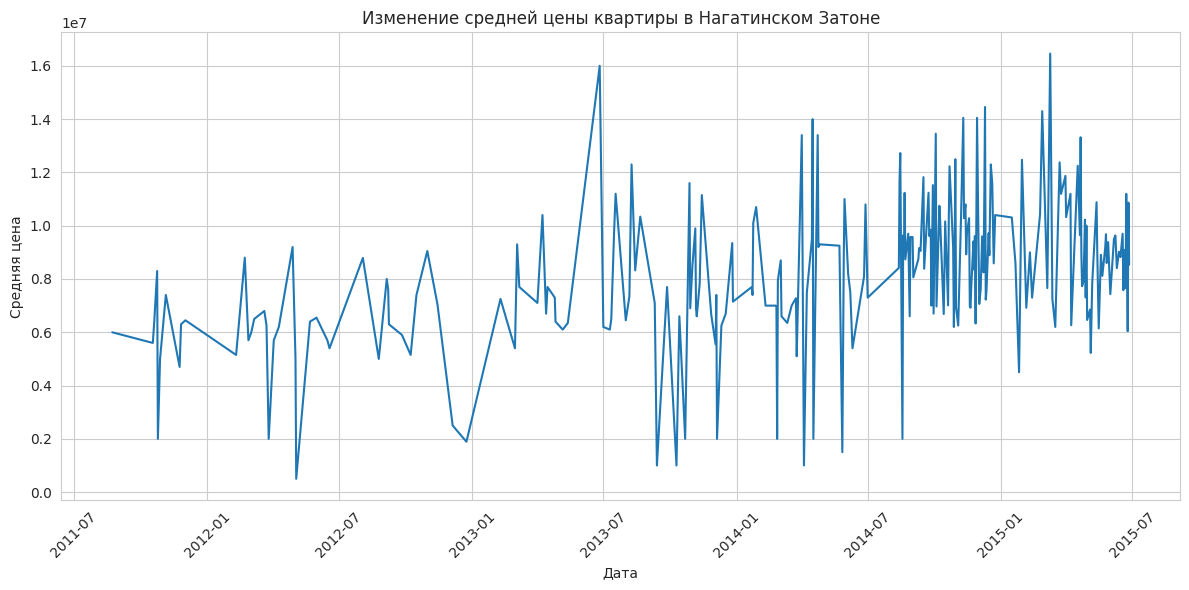

In [43]:
nagatinski_df = df[df['sub_area'] == 'Nagatinskij Zaton'].copy()
nagatinski_df['timestamp'] = pd.to_datetime(nagatinski_df['timestamp'])
price_over_time = nagatinski_df.groupby('timestamp')['price_doc'].mean().reset_index()


plt.figure(figsize=(12, 6))
sns.lineplot(x='timestamp', y='price_doc', data=price_over_time)
plt.title('Изменение средней цены квартиры в Нагатинском Затоне')
plt.xlabel('Дата')
plt.ylabel('Средняя цена')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

2. Постройте гистограмму распределения цен на квартиры с общей площадью более 50 кв.метров

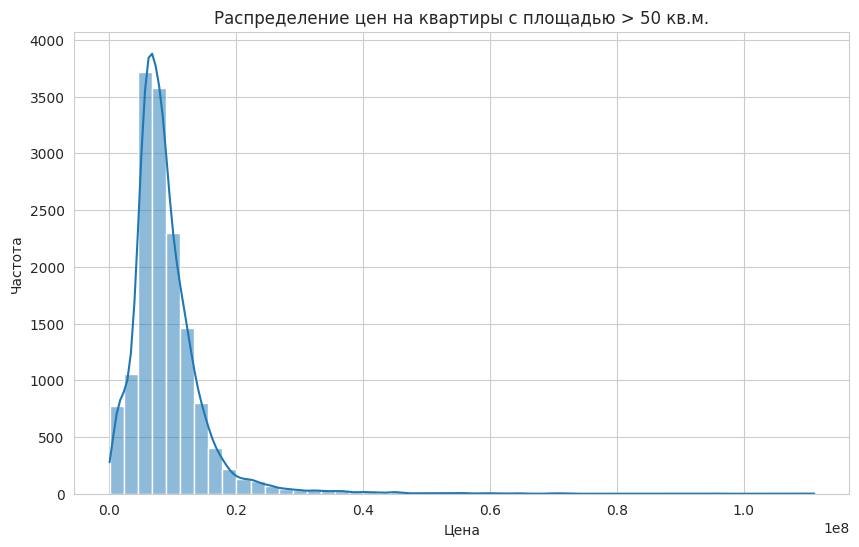

In [44]:
large_apartments = df[df['full_sq'] > 50]

plt.figure(figsize=(10, 6))
sns.histplot(large_apartments['price_doc'], bins=50, kde=True)
plt.title('Распределение цен на квартиры с площадью > 50 кв.м.')
plt.xlabel('Цена')
plt.ylabel('Частота')
plt.show()

3. Визуализируйте количество проданных квартир в разных районах

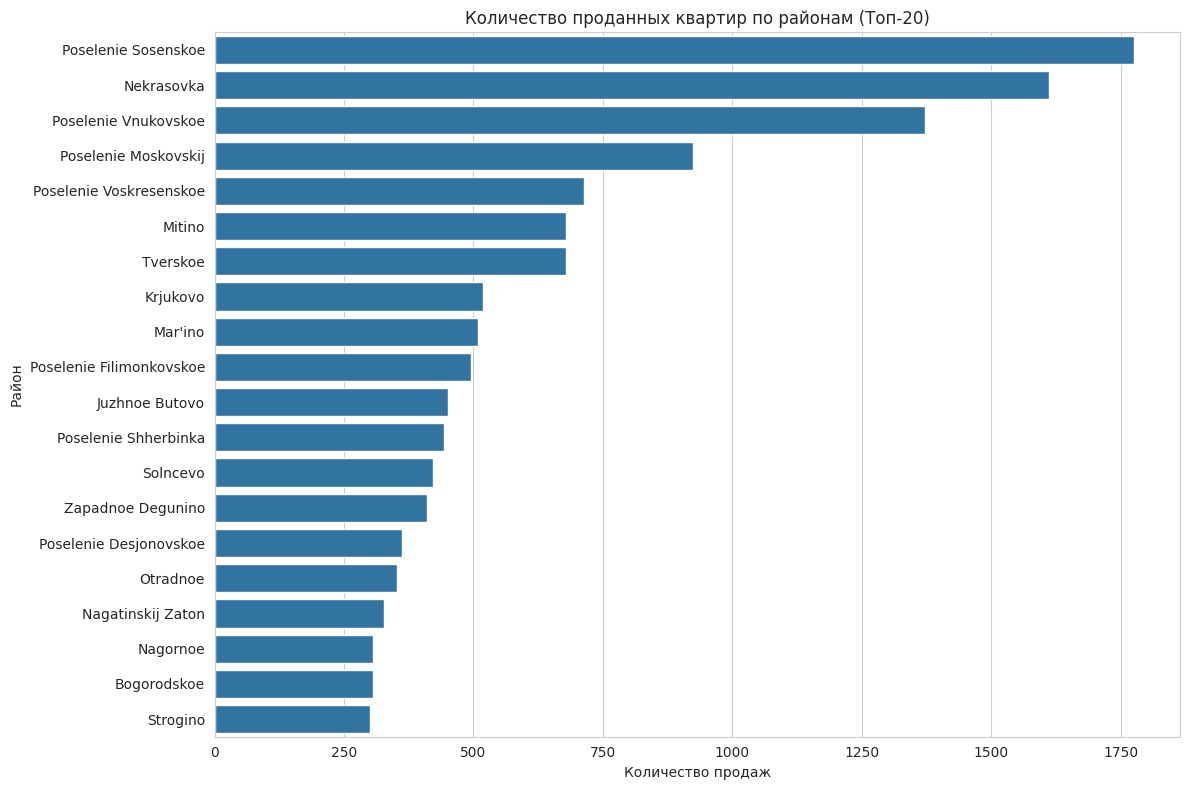

In [45]:
# для читаемости в вертикальном барплоте оставил только 20.
# ниже приведу полный барплот со всеми
sales_by_district = df['sub_area'].value_counts().reset_index()
sales_by_district.columns = ['sub_area', 'count']

top_20_districts = sales_by_district.head(20)

plt.figure(figsize=(12, 8))
sns.barplot(y='sub_area', x='count', data=top_20_districts)
plt.title('Количество проданных квартир по районам (Топ-20)')
plt.xlabel('Количество продаж')
plt.ylabel('Район')
plt.tight_layout()
plt.show()

Количество уникальных районов в датасете: 146


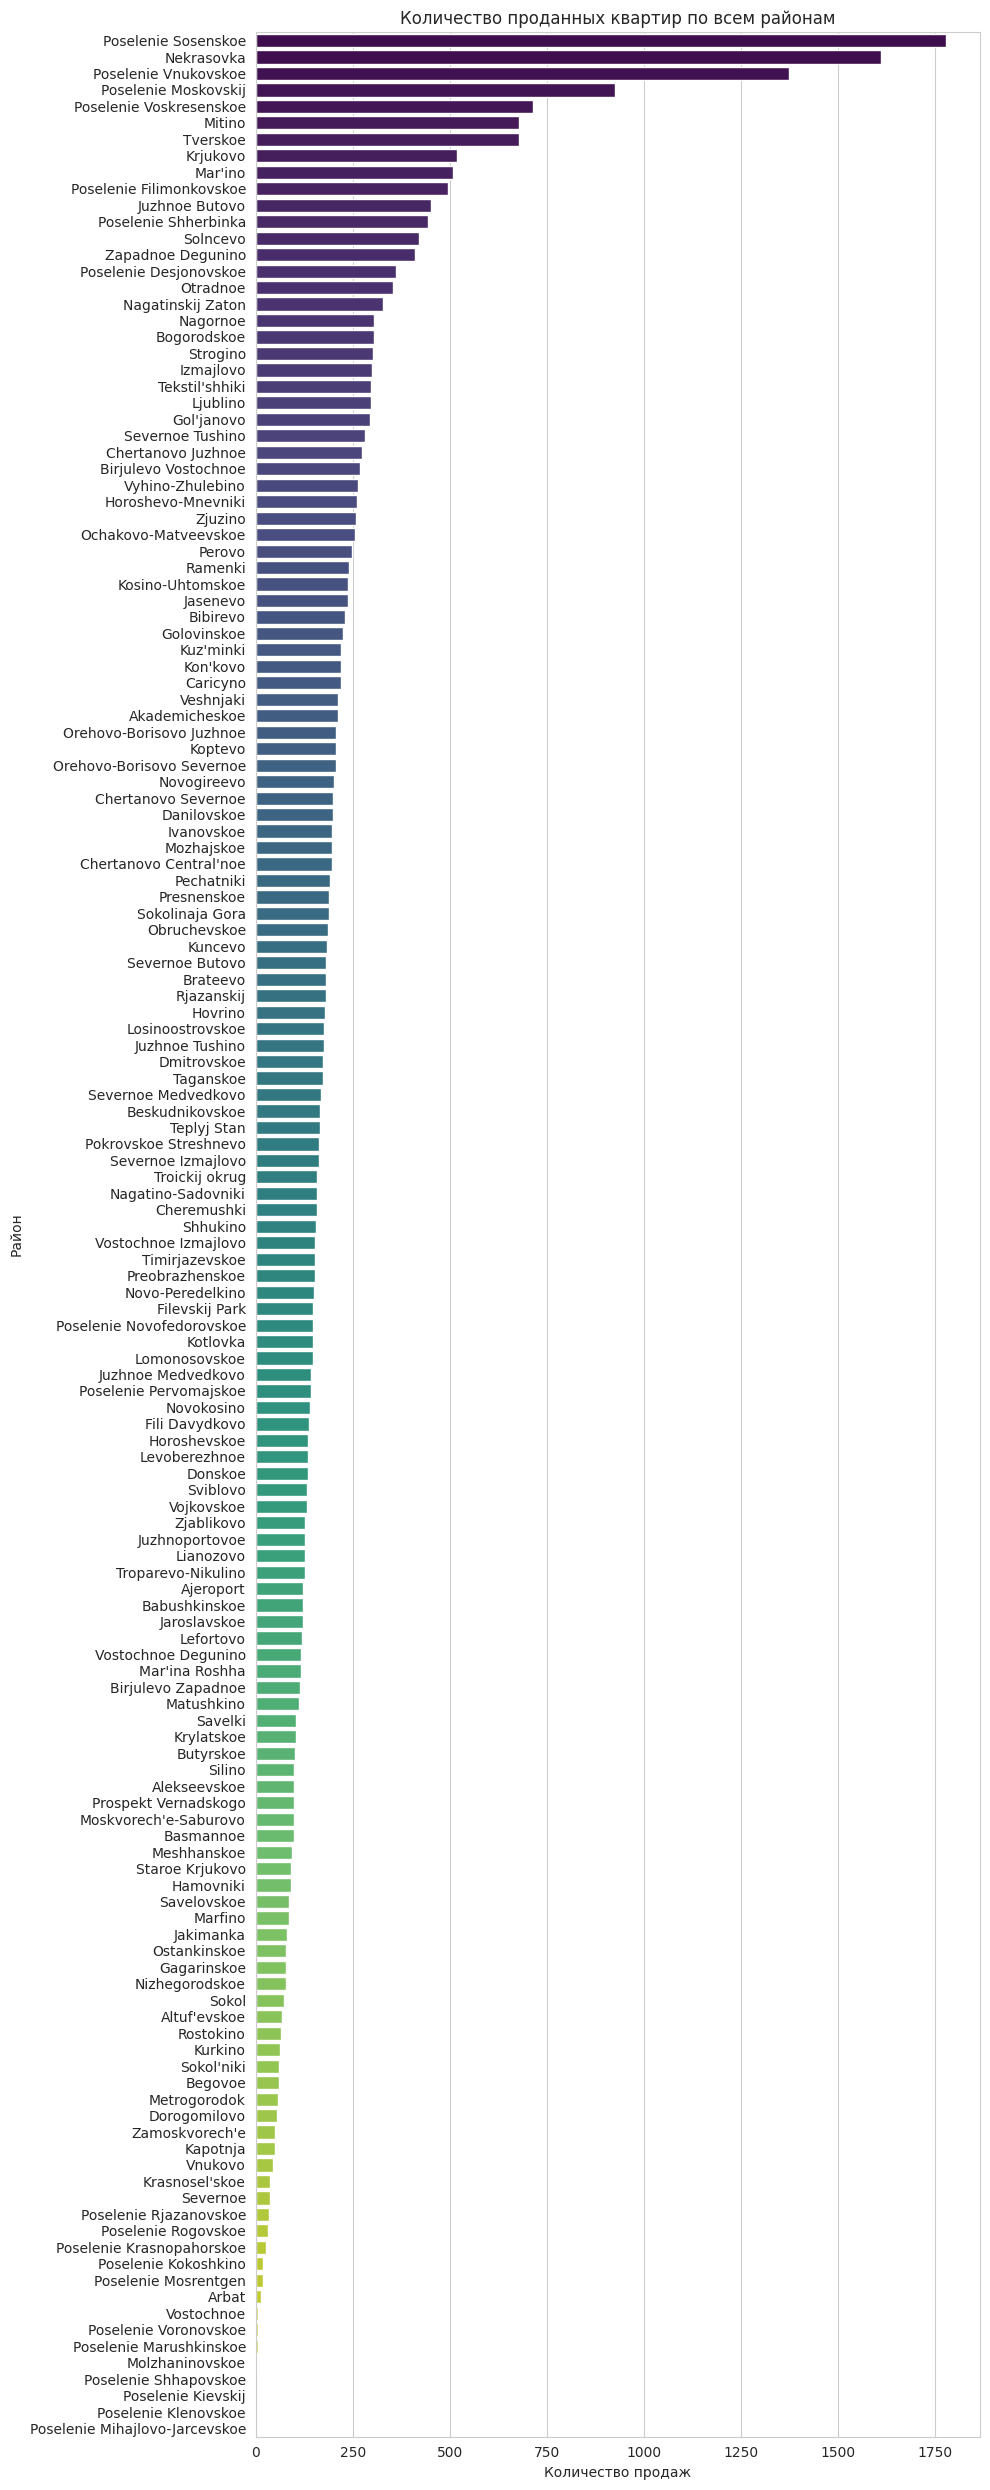

In [53]:
num_districts = df['sub_area'].nunique()
print(f"Количество уникальных районов в датасете: {num_districts}")

sales_by_district = df['sub_area'].value_counts().reset_index()
sales_by_district.columns = ['sub_area', 'count']

plt.figure(figsize=(10, 25)) # Делаем график очень высоким, чтобы все подписи влезли
sns.barplot(
    y='sub_area',
    x='count',
    data=sales_by_district,
    palette='viridis',
    hue='sub_area',   # <-- исправление
    legend=False      # <-- исправление
)
plt.title('Количество проданных квартир по всем районам')
plt.xlabel('Количество продаж')
plt.ylabel('Район')
plt.tight_layout()
plt.show()

4. Постройте box plot отображающий распределение полных площадей квартир в Басманном районе

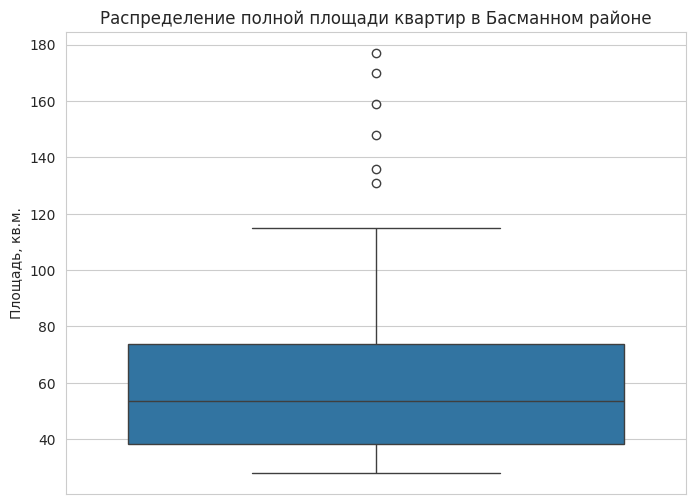

In [46]:
basmannoe_df = df[df['sub_area'] == 'Basmannoe']

plt.figure(figsize=(8, 6))
sns.boxplot(y=basmannoe_df['full_sq'])
plt.title('Распределение полной площади квартир в Басманном районе')
plt.ylabel('Площадь, кв.м.')
plt.show()

5. Визуализируйте зависимость средней стоимости квартир в зависимости от этажа

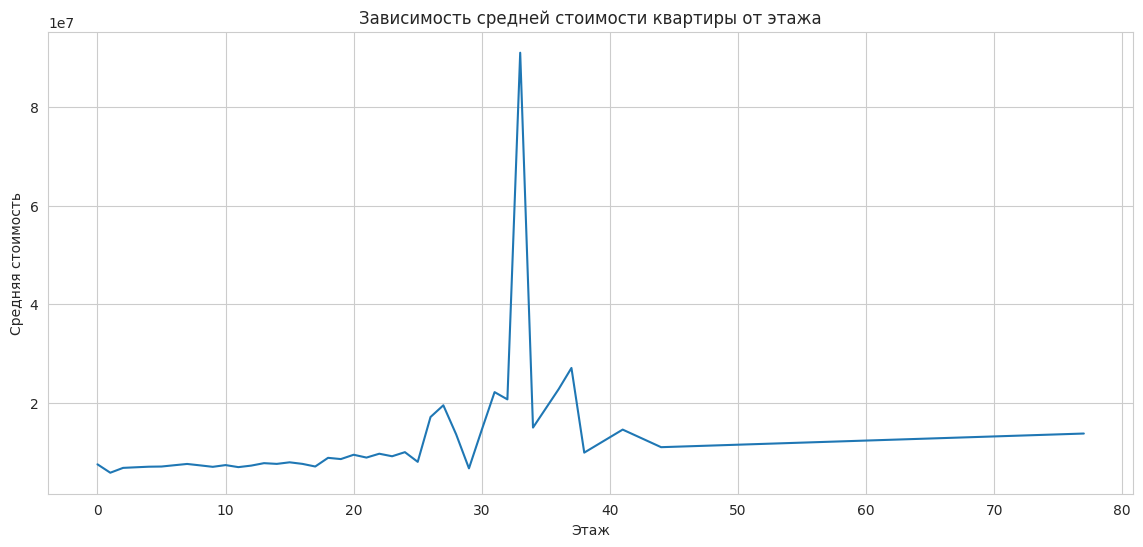

In [47]:
avg_price_by_floor = df.groupby('floor')['price_doc'].mean().reset_index()

plt.figure(figsize=(14, 6))
sns.lineplot(x='floor', y='price_doc', data=avg_price_by_floor)
plt.title('Зависимость средней стоимости квартиры от этажа')
plt.xlabel('Этаж')
plt.ylabel('Средняя стоимость')
plt.show()

6. Покажите как меняется средняя площадь квартир в зависимости от района

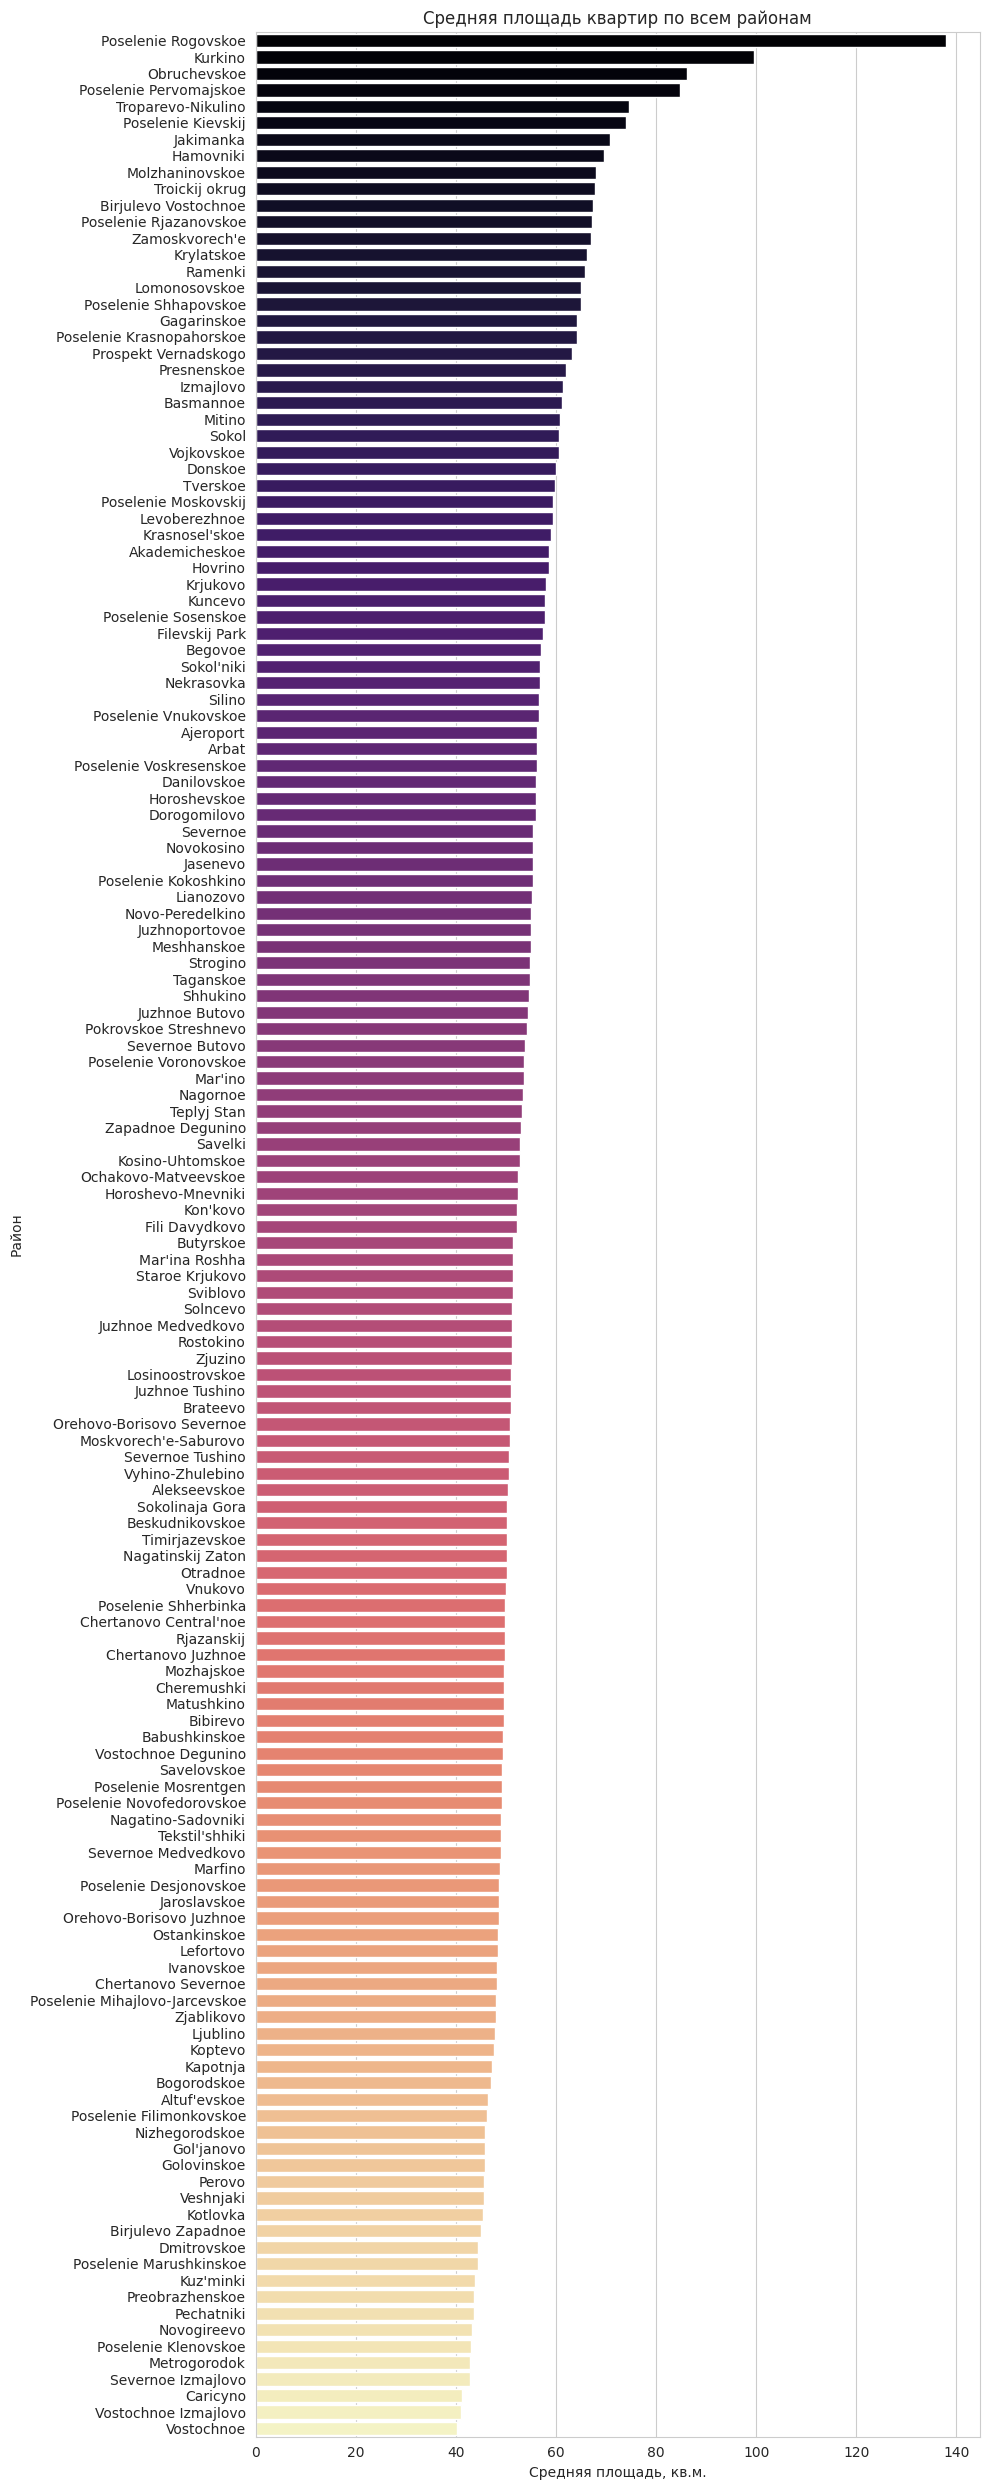

In [54]:
avg_sq_by_district = df.groupby('sub_area')['full_sq'].mean().reset_index()

avg_sq_by_district = avg_sq_by_district.sort_values(by='full_sq', ascending=False)

plt.figure(figsize=(10, 25)) # Высокий график для всех категорий
sns.barplot(
    y='sub_area',
    x='full_sq',
    data=avg_sq_by_district,
    palette='magma',
    hue='sub_area',   # <-- исправление
    legend=False      # <-- исправление
)
plt.title('Средняя площадь квартир по всем районам')
plt.xlabel('Средняя площадь, кв.м.')
plt.ylabel('Район')
plt.tight_layout()
plt.show()

7. Постройте график изменения медианной цены на квартиру менее 50 кв. метров за период с 2011 до 2014 года*

\* Задание на доп. балл

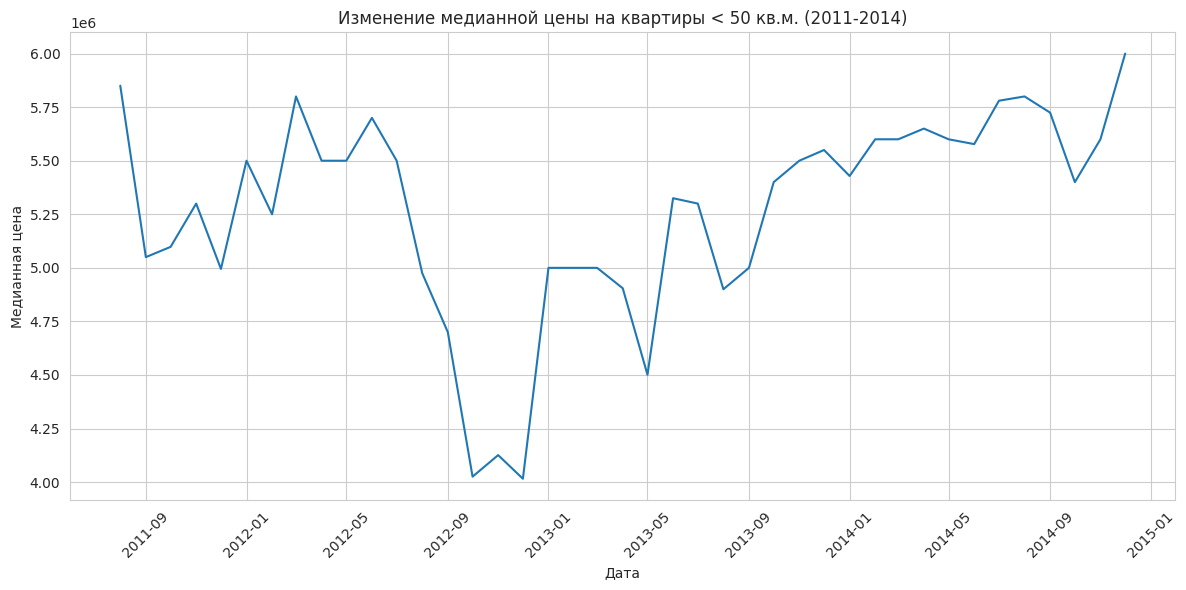

In [50]:
small_apartments_df = df[df['full_sq'] < 50].copy()
small_apartments_df['timestamp'] = pd.to_datetime(small_apartments_df['timestamp'])

start_date = '2011-01-01'
end_date = '2014-12-31'
mask = (small_apartments_df['timestamp'] >= start_date) & (small_apartments_df['timestamp'] <= end_date)
filtered_df = small_apartments_df.loc[mask].copy()

filtered_df['year_month'] = filtered_df['timestamp'].dt.to_period('M')
median_price_over_time = filtered_df.groupby('year_month')['price_doc'].median().reset_index()

median_price_over_time['year_month'] = median_price_over_time['year_month'].dt.to_timestamp()

plt.figure(figsize=(12, 6))
sns.lineplot(x='year_month', y='price_doc', data=median_price_over_time)
plt.title('Изменение медианной цены на квартиры < 50 кв.м. (2011-2014)')
plt.xlabel('Дата')
plt.ylabel('Медианная цена')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()